In [ ]:
from google.colab import drive
import os

# Montage de Google Drive
drive.mount('/content/drive')

# Création d'un dossier de travail dédié au projet sur votre Drive
drive_data_path = '/content/drive/MyDrive/UK_DALE_Project/data_raw'
os.makedirs(drive_data_path, exist_ok=True)

print(f"📁 Dossier de destination prêt dans Google Drive : {drive_data_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📁 Dossier de destination prêt dans Google Drive : /content/drive/MyDrive/UK_DALE_Project/data_raw


In [ ]:
scale = 2**31

u = block[:, 0] * cal["volts_per_adc_step"] * scale
i = block[:, 1] * cal["amps_per_adc_step"] * scale

u_rms = np.sqrt(np.mean(u ** 2))
i_rms = np.sqrt(np.mean(i ** 2))
p_mean = np.mean(u * i)

print(f"U_rms = {u_rms:.4f} V")
print(f"I_rms = {i_rms:.6f} A")
print(f"P_mean = {p_mean:.6f} W")

In [ ]:
import os
import subprocess
from google.colab import drive

# 1. Montage de Google Drive
drive.mount('/content/drive', force_remount=True)
target_dir = '/content/drive/MyDrive/UK_DALE_Project/data_raw/house_1/2013'
os.makedirs(target_dir, exist_ok=True)

# 2. Vos identifiants CEDA
CEDA_USERNAME = "sirineyedder0@gmail.com"
CEDA_PASSWORD = "**************"

# 3. URL officielle DAP fournie par le panier CEDA pour la maison 1 (année 2013)
dap_url = "https://dap.ceda.ac.uk/edc/d1/887733b3-4c04-471f-9404-9f7459c4a1a0/data/version_0/house_1/2013/"

print("🚀 Lancement du téléchargement officiel via le serveur DAP de CEDA...")

# Construction de la commande wget recommandée par CEDA
cmd = [
    "wget",
    f"--user={CEDA_USERNAME}",
    f"--password={CEDA_PASSWORD}",
    "-e", "robots=off",
    "--mirror",
    "--no-parent",
    "-r",
    "-P", target_dir,
    dap_url
]

# Exécution avec suivi en direct dans Colab
process = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in process.stdout:
    print(line, end='')

process.wait()

print(f"\n🏁 Téléchargement terminé ! Vérifiez votre dossier Google Drive : {target_dir}")

Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
151750K .......... .......... .......... .......... .......... 78% 50.0M 8s
151800K .......... .......... .......... .......... .......... 78% 41.2M 8s
151850K .......... .......... .......... .......... .......... 78% 11.6M 8s
151900K .......... .......... .......... .......... .......... 78% 50.4M 8s
151950K .......... .......... .......... .......... .......... 78% 54.1M 8s
152000K .......... .......... .......... .......... .......... 78% 55.2M 8s
152050K .......... .......... .......... .......... .......... 78% 43.1M 8s
152100K .......... .......... .......... .......... .......... 78% 28.7M 8s
152150K .......... .......... .......... .......... .......... 78% 48.5M 8s
152200K .......... .......... .......... .......... .......... 78% 55.3M 8s
152250K .......... .......... .......... .......... .......... 78% 57.0M 8s
152300K .......... .......... .......... .......... .......... 78% 53.0M 8s
152350K ..

KeyboardInterrupt: 

In [ ]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

# Remplacez "UK_DALE" par le nom de votre dossier racine dans Mon Drive
root = Path("/content/drive/MyDrive")

# Lister les dossiers correspondants sans cliquer partout
for p in root.rglob("*uk*dale*"):
    if p.is_dir():
        print(p)

In [ ]:
from pathlib import Path
import os

d1_dir = Path("/content/drive/MyDrive/UK_DALE_Project/data_raw/house_1/2013/dap.ceda.ac.uk/edc/d1")
assert d1_dir.exists(), f"Dossier introuvable : {d1_dir}"

week_items = sorted(d1_dir.iterdir())
print(f"Nombre d'éléments dans d1 : {len(week_items)}")

for item in week_items[:20]:
    if item.is_dir():
        size_mb = sum(f.stat().st_size for f in item.rglob("*") if f.is_file()) / (1024 ** 2)
        flac_count = len(list(item.rglob("*.flac")))
        print(f"  [DIR ] {item.name:<35} | {size_mb:8.2f} MB | {flac_count} .flac")
    else:
        size_mb = item.stat().st_size / (1024 ** 2)
        print(f"  [FILE] {item.name:<35} | {size_mb:8.2f} MB")

Nombre d'éléments dans d1 : 1
  [DIR ] 887733b3-4c04-471f-9404-9f7459c4a1a0 | 14951.02 MB | 80 .flac


In [ ]:
import shutil
from pathlib import Path

src_uuid_dir = Path(
    "/content/drive/MyDrive/UK_DALE_Project/data_raw/house_1/2013/dap.ceda.ac.uk/edc/d1/887733b3-4c04-471f-9404-9f7459c4a1a0"
)
dst_lot_dir = Path("/content/local_ukdale/d1_lot10gb")
dst_lot_dir.mkdir(parents=True, exist_ok=True)

target_bytes = 10 * 1024**3  # ~10 Go
copied_bytes = 0
copied_files = 0

all_flac = sorted(p for p in src_uuid_dir.rglob("*.flac") if p.is_file())
print(f"Total .flac trouvés dans {src_uuid_dir.name} : {len(all_flac)}")

for flac_path in all_flac:
    f_size = flac_path.stat().st_size
    if copied_files > 0 and copied_bytes + f_size > target_bytes:
        break
    # Conserver la structure relative sous dst_lot_dir
    rel_path = flac_path.relative_to(src_uuid_dir)
    dest_file = dst_lot_dir / rel_path
    dest_file.parent.mkdir(parents=True, exist_ok=True)
    if not dest_file.exists():
        shutil.copy2(flac_path, dest_file)
    copied_bytes += f_size
    copied_files += 1

print(
    f"Copie terminée : {copied_files}/{len(all_flac)} fichiers .flac | "
    f"Volume : {copied_bytes / (1024**3):.2f} GB ({copied_bytes / (1024**2):.1f} MB) -> {dst_lot_dir}"
)

Total .flac trouvés dans 887733b3-4c04-471f-9404-9f7459c4a1a0 : 80
Copie terminée : 54/80 fichiers .flac | Volume : 9.89 GB (10124.2 MB) -> /content/local_ukdale/d1_lot10gb


Fonction de décodage et fusion à la seconde

In [ ]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf

FLAC_TS_RE = re.compile(r"vi-(\d+)_(\d+)\.flac$")


def parse_flac_start_sec(fp: Path) -> float:
    """Extrait le timestamp Unix de départ (en secondes) depuis vi-<sec>_<usec>.flac."""
    m = FLAC_TS_RE.search(fp.name)
    if not m:
        raise ValueError(f"Nom de fichier UK-DALE inattendu : {fp.name}")
    sec = int(m.group(1))
    usec = int(m.group(2).ljust(6, "0")[:6])
    return sec + usec * 1e-6


def decode_flac_to_1s_partials(
    flac_path_str: str,
    scale_u: float,
    scale_i: float,
    block_sec: int = 60,
) -> pd.DataFrame:
    """
    Décode un fichier .flac en agrégats partiels par seconde Unix absolue (`sec_ts`).
    Conserve les sommes et effectifs (`n_samples`, `sum_u2`, `sum_i2`, `sum_ui`)
    pour fusionner sans biais les secondes coupées entre deux fichiers.
    """
    fp = Path(flac_path_str)
    t0_sec = parse_flac_start_sec(fp)
    partials: list[pd.DataFrame] = []

    with sf.SoundFile(str(fp), mode="r") as f:
        sr = int(f.samplerate)
        block_size = sr * block_sec
        sample_offset = 0

        for block in f.blocks(blocksize=block_size, dtype="int16", always_2d=True):
            n = len(block)
            if n == 0:
                continue

            b = block.astype(np.float64)
            u = b[:, 0] * scale_u
            i = b[:, 1] * scale_i if b.shape[1] >= 2 else np.zeros_like(u)

            # Timestamp absolu (seconde entière) de chaque échantillon
            ts = t0_sec + (sample_offset + np.arange(n, dtype=np.float64)) / sr
            sec_ts = np.floor(ts).astype(np.int64)

            df_blk = pd.DataFrame(
                {
                    "sec_ts": sec_ts,
                    "n_samples": 1,
                    "sum_u2": u * u,
                    "sum_i2": i * i,
                    "sum_ui": u * i,
                }
            )
            partials.append(df_blk.groupby("sec_ts", as_index=False).sum())
            sample_offset += n

    if not partials:
        return pd.DataFrame(columns=["sec_ts", "n_samples", "sum_u2", "sum_i2", "sum_ui"])

    return pd.concat(partials, ignore_index=True).groupby("sec_ts", as_index=False).sum()

Fusion entre fichiers + gestion des périodes manquantes

Une fois tous les fichiers décodés, on fusionne par sec_ts, on calcule u_rms et i_rms avec le diviseur $N$ exact (n_samples), et on segmente par continuité temporelle (segment_id) dès qu'il y a un trou (gap_sec > 1)

In [ ]:
def finalize_1s_series_pandas(partials_list: list[pd.DataFrame], min_samples_ratio: float = 0.9, sr: int = 16_000) -> pd.DataFrame:
    if not partials_list:
        return pd.DataFrame()

    # 1. Fusion des secondes coupées entre fichiers (somme des carrés et des effectifs)
    df = (
        pd.concat(partials_list, ignore_index=True)
        .groupby("sec_ts", as_index=False)
        .sum()
        .sort_values("sec_ts")
        .reset_index(drop=True)
    )

    # 2. Détection des trous temporels et secondes incomplètes (ex: bord de lot)
    df["gap_sec"] = df["sec_ts"].diff().fillna(1).astype(np.int64)
    df["is_complete_sec"] = df["n_samples"] >= int(sr * min_samples_ratio)
    df["segment_id"] = (df["gap_sec"] > 1).cumsum()

    # 3. Calcul exact de U_rms, I_rms et P_mean (diviseur N = n_samples)
    df["u_rms"] = np.sqrt(df["sum_u2"] / df["n_samples"])
    df["i_rms"] = np.sqrt(df["sum_i2"] / df["n_samples"])
    df["p_mean"] = df["sum_ui"] / df["n_samples"]

    # 4. Indicateurs temporels par segment continu (aucun calcul à travers un trou)
    grp = df.groupby("segment_id", sort=False)
    df["delta_u_rms"] = grp["u_rms"].diff()
    df["delta_i_rms"] = grp["i_rms"].diff()
    df["roll_i_rms_5s"] = grp["i_rms"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    df["roll_u_rms_5s"] = grp["u_rms"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

    return df[["sec_ts", "segment_id", "n_samples", "is_complete_sec", "u_rms", "i_rms", "p_mean",
               "delta_u_rms", "delta_i_rms", "roll_u_rms_5s", "roll_i_rms_5s"]]

In [ ]:
u_rms = float(np.sqrt(np.mean(u ** 2)))
i_rms = float(np.sqrt(np.mean(i ** 2)))
p_mean = float(np.mean(u * i))

print(f"Fichier test : {sample_flac.name}")
print(f"max|ch0|={np.max(np.abs(block[:, 0])):.4f} | max|ch1|={np.max(np.abs(block[:, 1])):.4f}")
print(f"U_rms = {u_rms:.4f} V | I_rms = {i_rms:.6f} A ({i_rms:.3e} A) | P_mean = {p_mean:.6f} W")
print("Calibration :", cal)

Fichier test : vi-1363406400_045853.flac
max|ch0|=0.8550 | max|ch1|=0.0334
U_rms = 244.4286 V | I_rms = 1.372122 A (1.372e+00 A) | P_mean = 307.920543 W
Calibration : {'volts_per_adc_step': 1.90101491444e-07, 'phase_difference': -2.92555759986, 'amps_per_adc_step': 4.9224284384e-08}


In [ ]:
from pathlib import Path
import soundfile as sf

lot_dir = Path("/content/local_ukdale/d1_lot10gb")
sample_flac = next(lot_dir.rglob("*.flac"))
info = sf.info(str(sample_flac))
print(
    f"Fichier : {sample_flac.name} | sr={info.samplerate} Hz | "
    f"channels={info.channels} | frames={info.frames} | duration={info.duration:.1f}s"
)

Fichier : vi-1363406400_045853.flac | sr=16000 Hz | channels=2 | frames=57593173 | duration=3599.6s


In [ ]:
'''from configparser import ConfigParser
from pathlib import Path


def load_ukdale_calibration(cfg_path: Path) -> dict[str, float]:
    parser = ConfigParser()
    parser.read(cfg_path, encoding="utf-8")
    sec = parser["Calibration"]
    return {
        "volts_per_adc_step": float(sec["volts_per_adc_step"]),
        "phase_difference": float(sec["phase_difference"]),
        "amps_per_adc_step": float(sec["amps_per_adc_step"]),
    }'''

Transformer les fichiers FLAC bruts de UK-DALE en une série temporelle structurée à une résolution d’une seconde, puis à sauvegarder les résultats en Parquet et les informations de traçabilité dans un manifeste JSON.

In [ ]:
from configparser import ConfigParser
from datetime import datetime, timezone
import hashlib
import json
from pathlib import Path
import re
import numpy as np
import pandas as pd
import soundfile as sf

# 1. Configuration et dossiers isolés dans benchmark_results-25-11
LOT_DIR = Path("/content/local_ukdale/d1_lot10gb")
CFG_PATH = Path("/content/calibration_house_1.cfg")
BASE_PROJECT_DIR = Path("/content/drive/MyDrive/UK_DALE_Project")

RESULTS_DIR = BASE_PROJECT_DIR / "benchmark_results-25-11"
PARQUET_DIR = RESULTS_DIR / "parquet_1s"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PARQUET_DIR.mkdir(parents=True, exist_ok=True)

LOT_NAME = "lot10gb"
SPLIT_ROLE = "calibration"  # "calibration" ou "test" (ne jamais mélanger)
SCALE_ADC = float(2**31)    # Conversion validée pour soundfile(..., dtype="float64")
BLOCK_SEC = 60
MIN_SAMPLES_RATIO = 0.9

parser = ConfigParser()
parser.read(CFG_PATH, encoding="utf-8")
SCALE_U = float(parser["Calibration"]["volts_per_adc_step"]) * SCALE_ADC
SCALE_I = float(parser["Calibration"]["amps_per_adc_step"]) * SCALE_ADC

FLAC_TS_RE = re.compile(r"vi-(\d+)_(\d+)\.flac$")


def parse_flac_start_sec(fp: Path) -> float:
    m = FLAC_TS_RE.search(fp.name)
    if not m:
        raise ValueError(f"Nom de fichier UK-DALE inattendu : {fp.name}")
    sec = int(m.group(1))
    usec = int(m.group(2).ljust(6, "0")[:6])
    return sec + usec * 1e-6


def decode_flac_to_1s_partials(flac_path_str: str, scale_u: float, scale_i: float, block_sec: int = 60) -> pd.DataFrame:
    fp = Path(flac_path_str)
    t0_sec = parse_flac_start_sec(fp)
    partials: list[pd.DataFrame] = []

    with sf.SoundFile(str(fp), mode="r") as f:
        sr = int(f.samplerate)
        block_size = sr * block_sec
        sample_offset = 0

        for block in f.blocks(blocksize=block_size, dtype="float64", always_2d=True):
            n = len(block)
            if n == 0:
                continue

            u = block[:, 0] * scale_u
            i = block[:, 1] * scale_i if block.shape[1] >= 2 else np.zeros_like(u)

            ts = t0_sec + (sample_offset + np.arange(n, dtype=np.float64)) / sr
            sec_ts = np.floor(ts).astype(np.int64)

            df_blk = pd.DataFrame(
                {
                    "sec_ts": sec_ts,
                    "n_samples": 1,
                    "sum_u2": u * u,
                    "sum_i2": i * i,
                    "sum_ui": u * i,
                }
            )
            partials.append(df_blk.groupby("sec_ts", as_index=False).sum())
            sample_offset += n

    if not partials:
        return pd.DataFrame(columns=["sec_ts", "n_samples", "sum_u2", "sum_i2", "sum_ui"])

    return pd.concat(partials, ignore_index=True).groupby("sec_ts", as_index=False).sum()


def finalize_1s_series(partials_list: list[pd.DataFrame], sr: int = 16_000, min_samples_ratio: float = 0.9) -> pd.DataFrame:
    if not partials_list:
        return pd.DataFrame()

    df = (
        pd.concat(partials_list, ignore_index=True)
        .groupby("sec_ts", as_index=False)
        .sum()
        .sort_values("sec_ts")
        .reset_index(drop=True)
    )

    df["gap_sec"] = df["sec_ts"].diff().fillna(1).astype(np.int64)
    df["is_complete_sec"] = df["n_samples"] >= int(sr * min_samples_ratio)
    df["segment_id"] = (df["gap_sec"] > 1).cumsum()

    df["u_rms"] = np.sqrt(df["sum_u2"] / df["n_samples"])
    df["i_rms"] = np.sqrt(df["sum_i2"] / df["n_samples"])
    df["p_mean"] = df["sum_ui"] / df["n_samples"]

    grp = df.groupby("segment_id", sort=False)
    df["delta_u_rms"] = grp["u_rms"].diff()
    df["delta_i_rms"] = grp["i_rms"].diff()
    df["roll_u_rms_5s"] = grp["u_rms"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    df["roll_i_rms_5s"] = grp["i_rms"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

    return df[
        [
            "sec_ts",
            "segment_id",
            "n_samples",
            "is_complete_sec",
            "u_rms",
            "i_rms",
            "p_mean",
            "delta_u_rms",
            "delta_i_rms",
            "roll_u_rms_5s",
            "roll_i_rms_5s",
        ]
    ]


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        while chunk := f.read(chunk_size):
            h.update(chunk)
    return h.hexdigest()


# 2. Exécution de l'extraction / structuration 1s + Parquet + manifeste
flac_files = sorted(p for p in LOT_DIR.rglob("*.flac") if p.is_file())
partials = [decode_flac_to_1s_partials(str(fp), SCALE_U, SCALE_I, BLOCK_SEC) for fp in flac_files]
df_1s = finalize_1s_series(partials, sr=16_000, min_samples_ratio=MIN_SAMPLES_RATIO)

parquet_path = PARQUET_DIR / f"{LOT_NAME}_1s.parquet"
df_1s.to_parquet(parquet_path, engine="pyarrow", index=False)

manifest = {
    "lot_name": LOT_NAME,
    "split_role": SPLIT_ROLE,
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "scale_adc": SCALE_ADC,
    "parquet_file": str(parquet_path),
    "parquet_sha256": sha256_file(parquet_path),
    "rows_1s": int(len(df_1s)),
    "segments_count": int(df_1s["segment_id"].nunique()) if not df_1s.empty else 0,
    "u_rms_median": float(df_1s["u_rms"].median()) if not df_1s.empty else None,
    "i_rms_median": float(df_1s["i_rms"].median()) if not df_1s.empty else None,
    "flac_files_count": len(flac_files),
    "files": [
        {
            "file_name": fp.name,
            "size_bytes": fp.stat().st_size,
            "mtime_utc": datetime.fromtimestamp(fp.stat().st_mtime, tz=timezone.utc).isoformat(),
            "sha256": sha256_file(fp),
        }
        for fp in flac_files
    ],
}

manifest_path = RESULTS_DIR / f"manifest_{LOT_NAME}.json"
manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")

print(f"Terminé : {len(df_1s)} lignes (1s), {manifest['segments_count']} segments")
print(f"Médiane U_rms = {manifest['u_rms_median']:.2f} V | Médiane I_rms = {manifest['i_rms_median']:.4f} A")
print(f"Parquet : {parquet_path}")
print(f"Manifeste : {manifest_path}")

Terminé : 190457 lignes (1s), 4 segments
Médiane U_rms = 243.13 V | Médiane I_rms = 1.0564 A
Parquet : /content/drive/MyDrive/UK_DALE_Project/benchmark_results-25-11/parquet_1s/lot10gb_1s.parquet
Manifeste : /content/drive/MyDrive/UK_DALE_Project/benchmark_results-25-11/manifest_lot10gb.json


Etape d'extraction / structuration en série temporelle pour.Elle convertit un signal .flac brut en lignes tabulaires exploitables par les traitements analytiques.

In [ ]:
'''import pandas as pd
import numpy as np
import soundfile as sf
from pathlib import Path

def decode_flac_to_windows_df(
    flac_path: Path,
    cal: dict[str, float],
    window_sec: int = 60,
) -> pd.DataFrame:
    scale_u = cal["volts_per_adc_step"]
    scale_i = cal["amps_per_adc_step"]
    records = []

    with sf.SoundFile(str(flac_path), mode="r") as f:
        sr = int(f.samplerate)
        samples_per_win = sr * window_sec
        win_idx = 0

        for block in f.blocks(blocksize=samples_per_win, dtype="float64", always_2d=True):
            n = len(block)
            if n == 0:
                continue

            u = block[:, 0] * scale_u
            i = block[:, 1] * scale_i if block.shape[1] >= 2 else np.zeros_like(u)

            i_rms = float(np.sqrt(np.mean(i ** 2)))
            p_mean = float(np.mean(u * i))

            records.append(
                {
                    "file_name": flac_path.name,
                    "win_idx": win_idx,
                    "win_start_sec": win_idx * window_sec,
                    "n_samples": int(n),
                    "i_rms": i_rms,
                    "p_mean": p_mean,
                }
            )
            win_idx += 1

    return pd.DataFrame.from_records(records)'''

Sanity check sur 1 seul bloc de 60 s d'un seul fichier .flac
16 000 échantillons par seconde

In [ ]:
from configparser import ConfigParser
from pathlib import Path
import numpy as np
import soundfile as sf

LOT_DIR = Path("/content/local_ukdale/d1_lot10gb")
CFG_PATH = Path("/content/calibration_house_1.cfg")

parser = ConfigParser()
parser.read(CFG_PATH, encoding="utf-8")
cal = {
    "volts_per_adc_step": float(parser["Calibration"]["volts_per_adc_step"]),
    "phase_difference": float(parser["Calibration"]["phase_difference"]),
    "amps_per_adc_step": float(parser["Calibration"]["amps_per_adc_step"]),
}

sample_flac = next(LOT_DIR.rglob("*.flac"))
with sf.SoundFile(str(sample_flac), mode="r") as f:
    block = f.read(frames=16_000 * 60, dtype="float64", always_2d=True)  # 1 min à 16 kHz

# Conversion UK-DALE : valeurs FLAC normalisées vers unités physiques
scale = 2**31

u = block[:, 0] * cal["volts_per_adc_step"] * scale
i = block[:, 1] * cal["amps_per_adc_step"] * scale

i_rms = float(np.sqrt(np.mean(i ** 2)))
p_mean = float(np.mean(u * i))

print(f"Fichier test : {sample_flac.name}")
print(f"max|ch0|={np.max(np.abs(block[:, 0])):.4f} | max|ch1|={np.max(np.abs(block[:, 1])):.4f}")
print(f"I_rms (1 min) = {i_rms:.6f} A | P_mean (1 min) = {p_mean:.6f} W")
#le canal 0 tension u

Fichier test : vi-1363406400_045853.flac
max|ch0|=0.8550 | max|ch1|=0.0334
I_rms (1 min) = 1.372122 A | P_mean (1 min) = 307.920543 W


Lever l'ambiguïté d'échelle et d'ordre des canaux sur I_rms et P_mean

In [ ]:
import numpy as np
import soundfile as sf

# On réutilise `sample_flac` et `cal` déjà chargés
with sf.SoundFile(str(sample_flac), mode="r") as f:
    raw_f64 = f.read(frames=16_000 * 60, dtype="float64", always_2d=True)
    f.seek(0)
    raw_i16 = f.read(frames=16_000 * 60, dtype="int16", always_2d=True).astype(np.float64)

# Cas 1 : float64 direct * facteur .cfg
u1 = raw_f64[:, 0] * cal["volts_per_adc_step"]
i1 = raw_f64[:, 1] * cal["amps_per_adc_step"]
print(f"[float64 * cfg] I_rms = {np.sqrt(np.mean(i1**2)):.6e} A | P_mean = {np.mean(u1*i1):.6e} W")

# Cas 2 : comptes ADC bruts (int16) * facteur .cfg
u2 = raw_i16[:, 0] * cal["volts_per_adc_step"]
i2 = raw_i16[:, 1] * cal["amps_per_adc_step"]
print(f"[int16   * cfg] I_rms = {np.sqrt(np.mean(i2**2)):.6e} A | P_mean = {np.mean(u2*i2):.6e} W")

# Cas 3 : inversion des canaux (ch1 = U, ch0 = I) en float64 * cfg
u3 = raw_f64[:, 1] * cal["volts_per_adc_step"]
i3 = raw_f64[:, 0] * cal["amps_per_adc_step"]
print(f"[swap ch * cfg] I_rms = {np.sqrt(np.mean(i3**2)):.6e} A | P_mean = {np.mean(u3*i3):.6e} W")

[float64 * cfg] I_rms = 3.225809e-10 A | P_mean = 2.742067e-17 W
[int16   * cfg] I_rms = 1.057037e-05 A | P_mean = 2.944273e-08 W
[swap ch * cfg] I_rms = 2.963460e-08 A | P_mean = 2.742067e-17 W


BO

In [ ]:
'''from datetime import datetime, timezone
from pathlib import Path
import json
import time
from configparser import ConfigParser
import numpy as np
import pandas as pd
import soundfile as sf

LOT_DIR = Path("/content/local_ukdale/d1_lot10gb")
CFG_PATH = Path("/content/calibration_house_1.cfg")
RESULTS_DIR = Path("/content/drive/MyDrive/UK_DALE_Project/benchmark_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

LOT_NAME = "lot10gb"
WINDOW_SEC = 60  # 60s = 1 min
DEADLINE_S = 180.0

parser = ConfigParser()
parser.read(CFG_PATH, encoding="utf-8")
scale_u = float(parser["Calibration"]["volts_per_adc_step"])
scale_i = float(parser["Calibration"]["amps_per_adc_step"])


def run_b0_lot10gb() -> dict:
    flac_files = sorted(p for p in LOT_DIR.rglob("*.flac") if p.is_file())
    t0 = time.perf_counter()

    all_chunks = []
    for fp in flac_files:
        rows = []
        with sf.SoundFile(str(fp), mode="r") as f:
            sr = int(f.samplerate)
            step = sr * WINDOW_SEC
            win_idx = 0
            for block in f.blocks(blocksize=step, dtype="int16", always_2d=True):
                if len(block) == 0:
                    continue
                b = block.astype(np.float64)
                u = b[:, 0] * scale_u
                i = b[:, 1] * scale_i if b.shape[1] >= 2 else np.zeros_like(u)
                rows.append(
                    {
                        "file_name": fp.name,
                        "win_idx": win_idx,
                        "win_start_sec": win_idx * WINDOW_SEC,
                        "n_samples": len(b),
                        "i_rms": float(np.sqrt(np.mean(i ** 2))),
                        "p_mean": float(np.mean(u * i)),
                    }
                )
                win_idx += 1

        if rows:
            df_f = pd.DataFrame.from_records(rows).sort_values("win_idx")
            df_f["delta_p_mean"] = df_f["p_mean"].diff().fillna(0.0)
            df_f["delta_i_rms"] = df_f["i_rms"].diff().fillna(0.0)
            df_f["hist_roll_p_mean_5"] = df_f["p_mean"].shift(1).rolling(5, min_periods=1).mean().fillna(0.0)
            df_f["hist_roll_i_rms_5"] = df_f["i_rms"].shift(1).rolling(5, min_periods=1).mean().fillna(0.0)
            all_chunks.append(df_f)

    final_df = pd.concat(all_chunks, ignore_index=True) if all_chunks else pd.DataFrame()
    duration_s = time.perf_counter() - t0

    metrics = {
        "code": "B0",
        "label": "Python local par blocs (soundfile + pandas + NumPy)",
        "lot": LOT_NAME,
        "nodes_p": 1,
        "partitions_P": 1,
        "aqe": False,
        "duration_s": round(duration_s, 4),
        "speedup_S": 1.0,
        "efficiency_E_pct": 100.0,
        "cost_node_s": round(duration_s, 4),
        "cost_node_min": round(duration_s / 60.0, 4),
        "deadline_s": DEADLINE_S,
        "respect_delai": duration_s <= DEADLINE_S,
        "output_rows": len(final_df),
        "flac_files_count": len(flac_files),
        "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    }

    out_json = RESULTS_DIR / f"b0_{LOT_NAME}.json"
    out_json.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    print(f"B0 terminé en {duration_s:.2f}s ({len(final_df)} lignes) -> {out_json}")
    return metrics


res_b0 = run_b0_lot10gb()'''

B0 terminé en 178.15s (3175 lignes) -> /content/drive/MyDrive/UK_DALE_Project/benchmark_results/b0_lot10gb.json


In [ ]:
from datetime import datetime, timezone
import json
from pathlib import Path
import time
import numpy as np
import pandas as pd

BASE_PROJECT_DIR = Path("/content/drive/MyDrive/UK_DALE_Project")
RESULTS_DIR = BASE_PROJECT_DIR / "benchmark_results-25-11"
PARQUET_PATH = RESULTS_DIR / "parquet_1s" / "lot10gb_1s.parquet"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

LOT_NAME = "lot10gb"
DEADLINE_S = 180.0


def run_b0_from_parquet(parquet_path: Path = PARQUET_PATH) -> dict:
    t0 = time.perf_counter()

    df = pd.read_parquet(parquet_path, engine="pyarrow").sort_values(["segment_id", "sec_ts"]).reset_index(drop=True)

    grp = df.groupby("segment_id", sort=False)
    df["delta_u_rms"] = grp["u_rms"].diff()
    df["delta_i_rms"] = grp["i_rms"].diff()
    df["delta_p_mean"] = grp["p_mean"].diff()
    df["roll_u_rms_5s"] = grp["u_rms"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    df["roll_i_rms_5s"] = grp["i_rms"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    df["roll_p_mean_5s"] = grp["p_mean"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

    out_parquet = RESULTS_DIR / f"b0_out_{LOT_NAME}.parquet"
    df.to_parquet(out_parquet, engine="pyarrow", index=False)

    duration_s = time.perf_counter() - t0

    metrics = {
        "code": "B0",
        "label": "Python local optimisé sur Parquet 1s (pandas + NumPy + PyArrow)",
        "lot": LOT_NAME,
        "nodes_p": 1,
        "partitions_P": 1,
        "aqe": False,
        "duration_s": round(duration_s, 4),
        "speedup_S": 1.0,
        "efficiency_E_pct": 100.0,
        "cost_node_s": round(duration_s, 4),
        "cost_node_min": round(duration_s / 60.0, 4),
        "deadline_s": DEADLINE_S,
        "respect_delai": duration_s <= DEADLINE_S,
        "output_rows": int(len(df)),
        "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    }

    out_json = RESULTS_DIR / f"b0_{LOT_NAME}.json"
    out_json.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    print(f"[B0] T={duration_s:.4f}s | lignes={len(df)} -> {out_json}")
    return metrics

In [ ]:
from pathlib import Path

res_dir = Path("/content/drive/MyDrive/UK_DALE_Project/benchmark_results-25-11")
pq_dir = res_dir / "parquet_1s"

print("Fichiers dans parquet_1s :", [p.name for p in pq_dir.glob("*")])
print("Fichiers dans benchmark_results-25-11 :", [p.name for p in res_dir.glob("*")])

Fichiers dans parquet_1s : ['lot10gb_1s.parquet']
Fichiers dans benchmark_results-25-11 : ['parquet_1s', 'manifest_lot10gb.json']


In [ ]:
res_b0 = run_b0_from_parquet()

[B0] T=1.3756s | lignes=190457 -> /content/drive/MyDrive/UK_DALE_Project/benchmark_results-25-11/b0_lot10gb.json


B1 → B4
Dans ce script, B4 était appelé avec un couple fixé en dur (nodes_p=4, partitions_p=128, aqe=True) afin de vérifier le fonctionnement de bout en bout du pipeline, et non par sélection automatique via un modèle prédictif de $T(p, P)$.

In [ ]:
'''import json
import time
from configparser import ConfigParser
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

LOT_DIR = Path("/content/local_ukdale/d1_lot10gb")
CFG_PATH = Path("/content/calibration_house_1.cfg")
RESULTS_DIR = Path("/content/drive/MyDrive/UK_DALE_Project/benchmark_results")
EVENTS_BASE_DIR = Path("/content/spark_events")

LOT_NAME = "lot10gb"
WINDOW_SEC = 60
DEADLINE_S = 180.0

parser = ConfigParser()
parser.read(CFG_PATH, encoding="utf-8")
SCALE_U = float(parser["Calibration"]["volts_per_adc_step"])
SCALE_I = float(parser["Calibration"]["amps_per_adc_step"])

B0_DURATION_S = float(json.loads((RESULTS_DIR / f"b0_{LOT_NAME}.json").read_text(encoding="utf-8"))["duration_s"])


def decode_and_treat_a_file(flac_path_str: str, window_sec: int, scale_u: float, scale_i: float) -> pd.DataFrame:
    fp = Path(flac_path_str)
    rows = []
    with sf.SoundFile(str(fp), mode="r") as f:
        sr = int(f.samplerate)
        step = sr * window_sec
        win_idx = 0
        for block in f.blocks(blocksize=step, dtype="int16", always_2d=True):
            if len(block) == 0:
                continue
            b = block.astype(np.float64)
            u = b[:, 0] * scale_u
            i = b[:, 1] * scale_i if b.shape[1] >= 2 else np.zeros_like(u)
            rows.append(
                {
                    "file_name": fp.name,
                    "win_idx": win_idx,
                    "win_start_sec": win_idx * window_sec,
                    "n_samples": len(b),
                    "i_rms": float(np.sqrt(np.mean(i ** 2))),
                    "p_mean": float(np.mean(u * i)),
                }
            )
            win_idx += 1
    return pd.DataFrame.from_records(rows)


def run_spark_benchmark(
    code: str,
    label: str,
    slug: str,
    master_expr: str,
    nodes_p: int,
    partitions_p: int,
    aqe: bool,
) -> dict:
    event_dir = EVENTS_BASE_DIR / slug
    event_dir.mkdir(parents=True, exist_ok=True)
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)

    flac_files = [str(p) for p in sorted(LOT_DIR.rglob("*.flac")) if p.is_file()]
    scale_u = SCALE_U
    scale_i = SCALE_I
    win_sec = WINDOW_SEC

    spark = (
        SparkSession.builder.appName(f"ukdale-{code.lower()}-{LOT_NAME}")
        .master(master_expr)
        .config("spark.eventLog.enabled", "true")
        .config("spark.eventLog.dir", event_dir.as_uri())
        .config("spark.sql.shuffle.partitions", str(partitions_p))
        .config("spark.sql.adaptive.enabled", "true" if aqe else "false")
        .getOrCreate()
    )

    try:
        t0 = time.perf_counter()

        files_df = spark.createDataFrame([(f,) for f in flac_files], ["flac_path"]).repartition(partitions_p)
        out_schema = (
            "file_name string, win_idx long, win_start_sec long, "
            "n_samples long, i_rms double, p_mean double"
        )

        def decode_partition(iterator):
            for pdf in iterator:
                out_chunks = []
                for p_str in pdf["flac_path"]:
                    df_w = decode_and_treat_a_file(p_str, win_sec, scale_u, scale_i)
                    if not df_w.empty:
                        out_chunks.append(df_w)
                if out_chunks:
                    yield pd.concat(out_chunks, ignore_index=True)
                else:
                    yield pd.DataFrame(columns=["file_name", "win_idx", "win_start_sec", "n_samples", "i_rms", "p_mean"])

        # Traitement A : agrégations par fenêtre
        agg_df = (
            files_df.mapInPandas(decode_partition, schema=out_schema)
            .groupBy("file_name", "win_idx", "win_start_sec")
            .agg(
                F.sum("n_samples").alias("n_samples"),
                F.sqrt(F.avg(F.col("i_rms") ** 2)).alias("i_rms"),
                F.avg("p_mean").alias("p_mean"),
            )
        )

        # Traitement B : variation inter-fenêtres + moyenne historique sur 5 fenêtres précédentes
        w_order = Window.partitionBy("file_name").orderBy("win_idx")
        w_hist5 = Window.partitionBy("file_name").orderBy("win_idx").rowsBetween(-5, -1)

        enriched_df = (
            agg_df.withColumn("delta_p_mean", F.col("p_mean") - F.lag("p_mean", 1).over(w_order))
            .withColumn("delta_i_rms", F.col("i_rms") - F.lag("i_rms", 1).over(w_order))
            .withColumn("hist_roll_p_mean_5", F.avg("p_mean").over(w_hist5))
            .withColumn("hist_roll_i_rms_5", F.avg("i_rms").over(w_hist5))
        )

        total_rows = enriched_df.count()
        duration_s = time.perf_counter() - t0

        speedup = B0_DURATION_S / duration_s if duration_s > 0 else 0.0
        efficiency_pct = (speedup / nodes_p * 100.0) if nodes_p > 0 else 0.0
        cost_s = nodes_p * duration_s
        cost_min = cost_s / 60.0

        metrics = {
            "code": code,
            "label": label,
            "lot": LOT_NAME,
            "nodes_p": nodes_p,
            "partitions_P": partitions_p,
            "aqe": aqe,
            "duration_s": round(duration_s, 4),
            "speedup_S": round(speedup, 4),
            "efficiency_E_pct": round(efficiency_pct, 2),
            "cost_node_s": round(cost_s, 4),
            "cost_node_min": round(cost_min, 4),
            "deadline_s": DEADLINE_S,
            "respect_delai": duration_s <= DEADLINE_S,
            "output_rows": total_rows,
            "flac_files_count": len(flac_files),
            "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
        }

        out_path = RESULTS_DIR / f"{code.lower()}_{LOT_NAME}.json"
        out_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
        print(f"[{code}] T={duration_s:.2f}s | S={speedup:.2f}x | E={efficiency_pct:.1f}% | p*T={cost_min:.2f} n-min -> {out_path.name}")
        return metrics
    finally:
        spark.stop()


# Exécution B1 -> B4
run_spark_benchmark("B1", "PySpark Mono-nœud (local[*])", "b1_mono_noeud", "local[*]", nodes_p=1, partitions_p=16, aqe=False)
run_spark_benchmark("B2", "PySpark Configuration Fixe + AQE", "b2_config_fixe_aqe", "local[4]", nodes_p=4, partitions_p=64, aqe=True)
run_spark_benchmark("B3", "PySpark Dimensionnement Ressources Seules", "b3_ressources_seules", "local[8]", nodes_p=8, partitions_p=64, aqe=True)
run_spark_benchmark("B4", "PySpark Choix Conjoint Proposé", "b4_choix_conjoint", "local[4]", nodes_p=4, partitions_p=128, aqe=True)'''

[B1] T=169.70s | S=1.05x | E=105.0% | p*T=2.83 n-min -> b1_lot10gb.json
[B2] T=159.59s | S=1.12x | E=27.9% | p*T=10.64 n-min -> b2_lot10gb.json
[B3] T=158.80s | S=1.12x | E=14.0% | p*T=21.17 n-min -> b3_lot10gb.json
[B4] T=159.58s | S=1.12x | E=27.9% | p*T=10.64 n-min -> b4_lot10gb.json


{'code': 'B4',
 'label': 'PySpark Choix Conjoint Proposé',
 'lot': 'lot10gb',
 'nodes_p': 4,
 'partitions_P': 128,
 'aqe': True,
 'duration_s': 159.577,
 'speedup_S': 1.1164,
 'efficiency_E_pct': 27.91,
 'cost_node_s': 638.308,
 'cost_node_min': 10.6385,
 'deadline_s': 180.0,
 'respect_delai': True,
 'output_rows': 3175,
 'flac_files_count': 54,
 'recorded_at_utc': '2026-11-21T10:30:48.643489+00:00'}

In [ ]:
import json
import time
from datetime import datetime, timezone
from pathlib import Path
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

BASE_PROJECT_DIR = Path("/content/drive/MyDrive/UK_DALE_Project")
RESULTS_DIR = BASE_PROJECT_DIR / "benchmark_results-25-11"
PARQUET_PATH = RESULTS_DIR / "parquet_1s" / "lot10gb_1s.parquet"
EVENTS_BASE_DIR = Path("/content/spark_events_25-11")

LOT_NAME = "lot10gb"
DEADLINE_S = 180.0

B0_DURATION_S = float(
    json.loads((RESULTS_DIR / f"b0_{LOT_NAME}.json").read_text(encoding="utf-8"))["duration_s"]
)


def run_spark_benchmark(
    code: str,
    label: str,
    slug: str,
    master_expr: str,
    nodes_p: int,
    partitions_p: int,
    aqe: bool,
    parquet_path: Path = PARQUET_PATH,
) -> dict:
    event_dir = EVENTS_BASE_DIR / slug
    event_dir.mkdir(parents=True, exist_ok=True)
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)

    spark = (
        SparkSession.builder.appName(f"ukdale-{code.lower()}-{LOT_NAME}-1s")
        .master(master_expr)
        .config("spark.eventLog.enabled", "true")
        .config("spark.eventLog.dir", event_dir.as_uri())
        .config("spark.sql.shuffle.partitions", str(partitions_p))
        .config("spark.sql.adaptive.enabled", "true" if aqe else "false")
        .getOrCreate()
    )

    try:
        t0 = time.perf_counter()

        raw_1s_df = spark.read.parquet(str(parquet_path))

        # Agrégation pondérée par effectif n_samples par seconde et segment
        agg_df = (
            raw_1s_df.groupBy("sec_ts", "segment_id")
            .agg(
                F.sum("n_samples").alias("n_samples"),
                F.sum(F.col("u_rms") ** 2 * F.col("n_samples")).alias("sum_u2"),
                F.sum(F.col("i_rms") ** 2 * F.col("n_samples")).alias("sum_i2"),
                F.sum(F.col("p_mean") * F.col("n_samples")).alias("sum_ui"),
            )
            .withColumn("u_rms", F.sqrt(F.col("sum_u2") / F.col("n_samples")))
            .withColumn("i_rms", F.sqrt(F.col("sum_i2") / F.col("n_samples")))
            .withColumn("p_mean", F.col("sum_ui") / F.col("n_samples"))
        )

        # Fenêtres strictement bornées au segment continu (pas de franchissement de trou)
        w_order = Window.partitionBy("segment_id").orderBy("sec_ts")
        w_hist5 = Window.partitionBy("segment_id").orderBy("sec_ts").rowsBetween(-5, -1)

        enriched_df = (
            agg_df.withColumn("delta_u_rms", F.col("u_rms") - F.lag("u_rms", 1).over(w_order))
            .withColumn("delta_i_rms", F.col("i_rms") - F.lag("i_rms", 1).over(w_order))
            .withColumn("delta_p_mean", F.col("p_mean") - F.lag("p_mean", 1).over(w_order))
            .withColumn("roll_u_rms_5s", F.avg("u_rms").over(w_hist5))
            .withColumn("roll_i_rms_5s", F.avg("i_rms").over(w_hist5))
            .withColumn("roll_p_mean_5s", F.avg("p_mean").over(w_hist5))
        )

        out_parquet = RESULTS_DIR / f"{code.lower()}_out_{LOT_NAME}.parquet"
        enriched_df.write.mode("overwrite").parquet(str(out_parquet))

        total_rows = spark.read.parquet(str(out_parquet)).count()
        duration_s = time.perf_counter() - t0

        speedup = B0_DURATION_S / duration_s if duration_s > 0 else 0.0
        efficiency_pct = (speedup / nodes_p * 100.0) if nodes_p > 0 else 0.0
        cost_s = nodes_p * duration_s
        cost_min = cost_s / 60.0

        metrics = {
            "code": code,
            "label": label,
            "lot": LOT_NAME,
            "nodes_p": nodes_p,
            "partitions_P": partitions_p,
            "aqe": aqe,
            "duration_s": round(duration_s, 4),
            "speedup_S": round(speedup, 4),
            "efficiency_E_pct": round(efficiency_pct, 2),
            "cost_node_s": round(cost_s, 4),
            "cost_node_min": round(cost_min, 4),
            "deadline_s": DEADLINE_S,
            "respect_delai": duration_s <= DEADLINE_S,
            "output_rows": total_rows,
            "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
        }

        out_path = RESULTS_DIR / f"{code.lower()}_{LOT_NAME}.json"
        out_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
        print(
            f"[{code}] T={duration_s:.2f}s | S={speedup:.2f}x | "
            f"E={efficiency_pct:.1f}% | p*T={cost_min:.4f} n-min | rows={total_rows} -> {out_path.name}"
        )
        return metrics
    finally:
        spark.stop()


# Exécution B1 -> B4
run_spark_benchmark("B1", "PySpark Mono-nœud (local[1])", "b1_mono_noeud", "local[1]", nodes_p=1, partitions_p=16, aqe=False)
run_spark_benchmark("B2", "PySpark Configuration Fixe + AQE", "b2_config_fixe_aqe", "local[4]", nodes_p=4, partitions_p=64, aqe=True)
run_spark_benchmark("B3", "PySpark Dimensionnement Ressources Seules", "b3_ressources_seules", "local[8]", nodes_p=8, partitions_p=64, aqe=True)
run_spark_benchmark("B4", "PySpark Choix Conjoint Proposé", "b4_choix_conjoint", "local[4]", nodes_p=4, partitions_p=128, aqe=True)

[B1] T=28.81s | S=0.05x | E=4.8% | p*T=0.4801 n-min | rows=190457 -> b1_lot10gb.json
[B2] T=11.71s | S=0.12x | E=2.9% | p*T=0.7809 n-min | rows=190457 -> b2_lot10gb.json
[B3] T=7.05s | S=0.20x | E=2.4% | p*T=0.9399 n-min | rows=190457 -> b3_lot10gb.json
[B4] T=9.42s | S=0.15x | E=3.7% | p*T=0.6279 n-min | rows=190457 -> b4_lot10gb.json


{'code': 'B4',
 'label': 'PySpark Choix Conjoint Proposé',
 'lot': 'lot10gb',
 'nodes_p': 4,
 'partitions_P': 128,
 'aqe': True,
 'duration_s': 9.4192,
 'speedup_S': 0.146,
 'efficiency_E_pct': 3.65,
 'cost_node_s': 37.6769,
 'cost_node_min': 0.6279,
 'deadline_s': 180.0,
 'respect_delai': True,
 'output_rows': 190457,
 'recorded_at_utc': '2026-11-25T15:55:07.375777+00:00'}

DecisionTree

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor


CANDIDATE_PAIRS: list[tuple[int, int]] = [
    (1, 16),
    (2, 32),
    (4, 32),
    (4, 64),
    (4, 128),
    (8, 64),
    (8, 128),
]


def load_training_runs(results_dir: Path, lot_dir: Path) -> pd.DataFrame:
    """Charge l'historique des runs JSON et complète si nécessaire pour entraîner l'arbre."""
    rows: list[dict] = []

    if results_dir.exists():
        for p in sorted(results_dir.glob("*.json")):
            try:
                data = json.loads(p.read_text(encoding="utf-8"))
                if "duration_s" in data and "nodes_p" in data and "partitions_P" in data:
                    lot_name = str(data.get("lot", ""))
                    # Estimation simple de la taille en Go à partir du nom de lot ou du dossier
                    if "10gb" in lot_name:
                        lot_gb = 10.0
                    elif "30gb" in lot_name:
                        lot_gb = 30.0
                    elif "100gb" in lot_name:
                        lot_gb = 100.0
                    else:
                        lot_gb = sum(f.stat().st_size for f in lot_dir.rglob("*.flac") if f.is_file()) / (1024**3)

                    rows.append(
                        {
                            "lot_gb": float(lot_gb),
                            "n_files": float(data.get("flac_files_count", 54)),
                            "nodes_p": int(data["nodes_p"]),
                            "partitions_P": int(data["partitions_P"]),
                            "duration_s": float(data["duration_s"]),
                        }
                    )
            except Exception:
                continue

    df_real = pd.DataFrame(rows)

    # Jeu d'amorçage léger uniquement si < 6 points réels pour éviter un arbre dégénéré
    if len(df_real) < 6:
        prior_rows = [
            {"lot_gb": 10.0, "n_files": 54.0, "nodes_p": 1, "partitions_P": 16, "duration_s": 169.7},
            {"lot_gb": 10.0, "n_files": 54.0, "nodes_p": 4, "partitions_P": 64, "duration_s": 159.6},
            {"lot_gb": 10.0, "n_files": 54.0, "nodes_p": 8, "partitions_P": 64, "duration_s": 158.8},
        ]
        df_prior = pd.DataFrame(prior_rows)
        return pd.concat([df_prior, df_real], ignore_index=True)

    return df_real


def choose_b4_with_decision_tree(
    results_dir: Path,
    lot_dir: Path,
    n_files: int,
    deadline_s: float = 180.0,
    candidate_pairs: list[tuple[int, int]] = CANDIDATE_PAIRS,
) -> dict:
    """Entraîne un DecisionTreeRegressor et choisit (p, P) minimisant p * T_pred sous D <= deadline_s."""
    lot_gb = sum(f.stat().st_size for f in lot_dir.rglob("*.flac") if f.is_file()) / (1024**3)
    train_df = load_training_runs(results_dir, lot_dir)

    features = ["lot_gb", "n_files", "nodes_p", "partitions_P"]
    model = DecisionTreeRegressor(max_depth=4, min_samples_leaf=1, random_state=42)
    model.fit(train_df[features], train_df["duration_s"])

    cand_df = pd.DataFrame(
        [
            {
                "lot_gb": float(lot_gb),
                "n_files": float(n_files),
                "nodes_p": int(p),
                "partitions_P": int(part),
            }
            for p, part in candidate_pairs
        ]
    )
    cand_df["pred_T_s"] = model.predict(cand_df[features])
    cand_df["pred_cost_s"] = cand_df["nodes_p"] * cand_df["pred_T_s"]
    cand_df["pred_cost_min"] = cand_df["pred_cost_s"] / 60.0
    cand_df["feasible"] = cand_df["pred_T_s"] <= deadline_s

    feasible_df = cand_df[cand_df["feasible"]]
    pool = feasible_df if not feasible_df.empty else cand_df.sort_values("pred_T_s")
    best = pool.sort_values(["pred_cost_s", "pred_T_s"]).iloc[0]

    return {
        "nodes_p": int(best["nodes_p"]),
        "partitions_P": int(best["partitions_P"]),
        "pred_T_s": round(float(best["pred_T_s"]), 4),
        "pred_cost_min": round(float(best["pred_cost_min"]), 4),
        "feasible_under_deadline": bool(best["feasible"]),
        "lot_gb_measured": round(float(lot_gb), 3),
        "train_rows_count": int(len(train_df)),
        "candidates_eval": cand_df.to_dict(orient="records"),
    }

inference

In [ ]:
flac_list = [str(p) for p in sorted(LOT_DIR.rglob("*.flac")) if p.is_file()]
dt_choice = choose_b4_with_decision_tree(
    results_dir=RESULTS_DIR,
    lot_dir=LOT_DIR,
    n_files=len(flac_list),
    deadline_s=DEADLINE_S,
)

best_p = dt_choice["nodes_p"]
best_P = dt_choice["partitions_P"]
master_b4 = f"local[{best_p}]"

print(
    f"[B4-DT] Choix arbre de décision -> p={best_p}, P={best_P} | "
    f"T_pred={dt_choice['pred_T_s']:.2f}s | p*T_pred={dt_choice['pred_cost_min']:.2f} n-min"
)

res_b4_dt = run_spark_benchmark(
    code="B4",
    label="PySpark Choix Conjoint Proposé (Arbre de Décision)",
    slug="b4_choix_conjoint_dt",
    master_expr=master_b4,
    nodes_p=best_p,
    partitions_p=best_P,
    aqe=True,
)

# Enrichir b4_<lot>.json avec les informations de décision de l'arbre
b4_json_path = RESULTS_DIR / f"b4_{LOT_NAME}.json"
b4_payload = json.loads(b4_json_path.read_text(encoding="utf-8"))
b4_payload["decision_tree"] = {
    "selected_nodes_p": best_p,
    "selected_partitions_P": best_P,
    "pred_T_s": dt_choice["pred_T_s"],
    "pred_cost_min": dt_choice["pred_cost_min"],
    "feasible_under_deadline": dt_choice["feasible_under_deadline"],
    "train_rows_count": dt_choice["train_rows_count"],
}
b4_json_path.write_text(json.dumps(b4_payload, indent=2), encoding="utf-8")

[B4-DT] Choix arbre de décision -> p=4, P=128 | T_pred=9.42s | p*T_pred=0.63 n-min
[B4] T=7.19s | S=0.19x | E=4.8% | p*T=0.4797 n-min | rows=190457 -> b4_lot10gb.json


628

In [ ]:

from google.colab import drive
from pathlib import Path
import json

# 1. Monter Google Drive
drive.mount('/content/drive')

# 2. Chemin du dossier des benchmarks
folder = Path(
    "/content/drive/MyDrive/UK_DALE_Project/benchmark_results-25-11"
)

# 3. Lire et afficher les fichiers JSON
for code in ["b0", "b1", "b2", "b3", "b4"]:
    file_path = folder / f"{code}_lot10gb.json"

    print("\n" + "=" * 70)
    print(f"FICHIER : {file_path.name}")
    print("=" * 70)

    if file_path.exists():
        with open(file_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        print(json.dumps(data, indent=4, ensure_ascii=False))
    else:
        print("Fichier introuvable !")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

FICHIER : b0_lot10gb.json
{
    "code": "B0",
    "label": "Python local optimisé sur Parquet 1s (pandas + NumPy + PyArrow)",
    "lot": "lot10gb",
    "nodes_p": 1,
    "partitions_P": 1,
    "aqe": false,
    "duration_s": 1.3756,
    "speedup_S": 1.0,
    "efficiency_E_pct": 100.0,
    "cost_node_s": 1.3756,
    "cost_node_min": 0.0229,
    "deadline_s": 180.0,
    "respect_delai": true,
    "output_rows": 190457,
    "recorded_at_utc": "2026-11-25T15:50:56.188233+00:00"
}

FICHIER : b1_lot10gb.json
{
    "code": "B1",
    "label": "PySpark Mono-nœud (local[1])",
    "lot": "lot10gb",
    "nodes_p": 1,
    "partitions_P": 16,
    "aqe": false,
    "duration_s": 28.8068,
    "speedup_S": 0.0478,
    "efficiency_E_pct": 4.78,
    "cost_node_s": 28.8068,
    "cost_node_min": 0.4801,
    "deadline_s": 180.0,
    "respect_delai": true,
    "output_rows": 19045

On passe vers la totalité de donnee

In [ ]:
import shutil
from pathlib import Path

src_uuid_dir = Path(
    "/content/drive/MyDrive/UK_DALE_Project/data_raw/house_1/2013/dap.ceda.ac.uk/edc/d1/887733b3-4c04-471f-9404-9f7459c4a1a0"
)
prev_lot_dir = Path("/content/local_ukdale/d1_lot10gb")
full_lot_dir = Path("/content/local_ukdale/d1_full")
full_lot_dir.mkdir(parents=True, exist_ok=True)

all_flac = sorted(p for p in src_uuid_dir.rglob("*.flac") if p.is_file())
total_bytes = 0
from_local = 0
from_drive = 0

for flac_path in all_flac:
    rel_path = flac_path.relative_to(src_uuid_dir)
    dest_file = full_lot_dir / rel_path
    dest_file.parent.mkdir(parents=True, exist_ok=True)

    if not dest_file.exists():
        cached_file = prev_lot_dir / rel_path
        if cached_file.exists():
            shutil.copy2(cached_file, dest_file)
            from_local += 1
        else:
            shutil.copy2(flac_path, dest_file)
            from_drive += 1

    total_bytes += dest_file.stat().st_size

print(
    f"Ensemble prêt : {len(all_flac)} fichiers .flac | "
    f"Volume total : {total_bytes / (1024**3):.2f} GB "
    f"(copiés depuis local : {from_local}, depuis Drive : {from_drive})"
)

Ensemble prêt : 80 fichiers .flac | Volume total : 14.60 GB (copiés depuis local : 54, depuis Drive : 26)


B0 → B4-DT sur d1_full

In [ ]:
'''import gc
import json
import time
from configparser import ConfigParser
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from sklearn.tree import DecisionTreeRegressor

LOT_DIR = Path("/content/local_ukdale/d1_full")
CFG_PATH = Path("/content/calibration_house_1.cfg")
RESULTS_DIR = Path("/content/drive/MyDrive/UK_DALE_Project/benchmark_results")
EVENTS_BASE_DIR = Path("/content/spark_events")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

LOT_NAME = "lot_full_15gb"
WINDOW_SEC = 60
DEADLINE_S = 180.0

parser = ConfigParser()
parser.read(CFG_PATH, encoding="utf-8")
SCALE_U = float(parser["Calibration"]["volts_per_adc_step"])
SCALE_I = float(parser["Calibration"]["amps_per_adc_step"])


def decode_and_treat_a_file(flac_path_str: str, window_sec: int, scale_u: float, scale_i: float) -> pd.DataFrame:
    fp = Path(flac_path_str)
    rows = []
    with sf.SoundFile(str(fp), mode="r") as f:
        sr = int(f.samplerate)
        step = sr * window_sec
        win_idx = 0
        for block in f.blocks(blocksize=step, dtype="int16", always_2d=True):
            if len(block) == 0:
                continue
            b = block.astype(np.float64)
            u = b[:, 0] * scale_u
            i = b[:, 1] * scale_i if b.shape[1] >= 2 else np.zeros_like(u)
            rows.append(
                {
                    "file_name": fp.name,
                    "win_idx": win_idx,
                    "win_start_sec": win_idx * window_sec,
                    "n_samples": len(b),
                    "i_rms": float(np.sqrt(np.mean(i ** 2))),
                    "p_mean": float(np.mean(u * i)),
                }
            )
            win_idx += 1
    return pd.DataFrame.from_records(rows)


def run_b0_full() -> float:
    flac_files = sorted(p for p in LOT_DIR.rglob("*.flac") if p.is_file())
    lot_gb = sum(p.stat().st_size for p in flac_files) / (1024**3)
    t0 = time.perf_counter()

    all_chunks = []
    for fp in flac_files:
        df_f = decode_and_treat_a_file(str(fp), WINDOW_SEC, SCALE_U, SCALE_I)
        if not df_f.empty:
            df_f = df_f.sort_values("win_idx")
            df_f["delta_p_mean"] = df_f["p_mean"].diff().fillna(0.0)
            df_f["delta_i_rms"] = df_f["i_rms"].diff().fillna(0.0)
            df_f["hist_roll_p_mean_5"] = df_f["p_mean"].shift(1).rolling(5, min_periods=1).mean().fillna(0.0)
            df_f["hist_roll_i_rms_5"] = df_f["i_rms"].shift(1).rolling(5, min_periods=1).mean().fillna(0.0)
            all_chunks.append(df_f)

    final_df = pd.concat(all_chunks, ignore_index=True) if all_chunks else pd.DataFrame()
    duration_s = time.perf_counter() - t0

    metrics = {
        "code": "B0",
        "label": "Python local par blocs (soundfile + pandas + NumPy)",
        "lot": LOT_NAME,
        "lot_gb": round(lot_gb, 3),
        "nodes_p": 1,
        "partitions_P": 1,
        "aqe": False,
        "duration_s": round(duration_s, 4),
        "speedup_S": 1.0,
        "efficiency_E_pct": 100.0,
        "cost_node_s": round(duration_s, 4),
        "cost_node_min": round(duration_s / 60.0, 4),
        "deadline_s": DEADLINE_S,
        "respect_delai": duration_s <= DEADLINE_S,
        "output_rows": len(final_df),
        "flac_files_count": len(flac_files),
        "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    (RESULTS_DIR / f"b0_{LOT_NAME}.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    print(f"[B0] T={duration_s:.2f}s | Respect délai (<=180s)={duration_s <= DEADLINE_S} | Lignes={len(final_df)}")
    gc.collect()
    return duration_s


def run_spark_step(
    code: str,
    label: str,
    slug: str,
    master_expr: str,
    nodes_p: int,
    partitions_p: int,
    aqe: bool,
    b0_duration_s: float,
    extra: dict | None = None,
) -> dict:
    event_dir = EVENTS_BASE_DIR / f"{slug}_{LOT_NAME}"
    event_dir.mkdir(parents=True, exist_ok=True)
    flac_files = [str(p) for p in sorted(LOT_DIR.rglob("*.flac")) if p.is_file()]
    lot_gb = sum(Path(p).stat().st_size for p in flac_files) / (1024**3)
    scale_u, scale_i, win_sec = SCALE_U, SCALE_I, WINDOW_SEC

    spark = (
        SparkSession.builder.appName(f"ukdale-{code.lower()}-{LOT_NAME}")
        .master(master_expr)
        .config("spark.eventLog.enabled", "true")
        .config("spark.eventLog.dir", event_dir.as_uri())
        .config("spark.sql.shuffle.partitions", str(partitions_p))
        .config("spark.sql.adaptive.enabled", "true" if aqe else "false")
        .getOrCreate()
    )

    try:
        t0 = time.perf_counter()
        files_df = spark.createDataFrame([(f,) for f in flac_files], ["flac_path"]).repartition(partitions_p)
        out_schema = (
            "file_name string, win_idx long, win_start_sec long, "
            "n_samples long, i_rms double, p_mean double"
        )

        def decode_partition(iterator):
            for pdf in iterator:
                chunks = [
                    df_w
                    for p_str in pdf["flac_path"]
                    if not (df_w := decode_and_treat_a_file(p_str, win_sec, scale_u, scale_i)).empty
                ]
                yield (
                    pd.concat(chunks, ignore_index=True)
                    if chunks
                    else pd.DataFrame(columns=["file_name", "win_idx", "win_start_sec", "n_samples", "i_rms", "p_mean"])
                )

        agg_df = (
            files_df.mapInPandas(decode_partition, schema=out_schema)
            .groupBy("file_name", "win_idx", "win_start_sec")
            .agg(
                F.sum("n_samples").alias("n_samples"),
                F.sqrt(F.avg(F.col("i_rms") ** 2)).alias("i_rms"),
                F.avg("p_mean").alias("p_mean"),
            )
        )

        w_order = Window.partitionBy("file_name").orderBy("win_idx")
        w_hist5 = Window.partitionBy("file_name").orderBy("win_idx").rowsBetween(-5, -1)

        enriched_df = (
            agg_df.withColumn("delta_p_mean", F.col("p_mean") - F.lag("p_mean", 1).over(w_order))
            .withColumn("delta_i_rms", F.col("i_rms") - F.lag("i_rms", 1).over(w_order))
            .withColumn("hist_roll_p_mean_5", F.avg("p_mean").over(w_hist5))
            .withColumn("hist_roll_i_rms_5", F.avg("i_rms").over(w_hist5))
        )

        total_rows = enriched_df.count()
        duration_s = time.perf_counter() - t0
        speedup = b0_duration_s / duration_s
        efficiency_pct = (speedup / nodes_p) * 100.0
        cost_s = nodes_p * duration_s
        cost_min = cost_s / 60.0

        metrics = {
            "code": code,
            "label": label,
            "lot": LOT_NAME,
            "lot_gb": round(lot_gb, 3),
            "nodes_p": nodes_p,
            "partitions_P": partitions_p,
            "aqe": aqe,
            "duration_s": round(duration_s, 4),
            "speedup_S": round(speedup, 4),
            "efficiency_E_pct": round(efficiency_pct, 2),
            "cost_node_s": round(cost_s, 4),
            "cost_node_min": round(cost_min, 4),
            "deadline_s": DEADLINE_S,
            "respect_delai": duration_s <= DEADLINE_S,
            "output_rows": total_rows,
            "flac_files_count": len(flac_files),
            "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
        }
        if extra:
            metrics["details"] = extra

        (RESULTS_DIR / f"{code.lower()}_{LOT_NAME}.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
        print(f"[{code}] T={duration_s:.2f}s | S={speedup:.2f}x | E={efficiency_pct:.1f}% | p*T={cost_min:.2f} n-min | D<=180s={duration_s <= DEADLINE_S}")
        return metrics
    finally:
        spark.stop()
        gc.collect()


def select_safe_b4_dt(results_dir: Path, lot_dir: Path, safety_ratio: float = 0.90) -> tuple[int, int, dict]:
    flac_files = [p for p in lot_dir.rglob("*.flac") if p.is_file()]
    lot_gb = sum(p.stat().st_size for p in flac_files) / (1024**3)
    n_files = float(len(flac_files))

    rows = []
    for p in sorted(results_dir.glob("*.json")):
        d = json.loads(p.read_text(encoding="utf-8"))
        if all(k in d for k in ("duration_s", "nodes_p", "partitions_P")):
            gb = float(d.get("lot_gb", 9.95 if "10gb" in str(d.get("lot", "")) else lot_gb))
            rows.append(
                {
                    "lot_gb": gb,
                    "n_files": float(d.get("flac_files_count", n_files)),
                    "nodes_p": int(d["nodes_p"]),
                    "partitions_P": int(d["partitions_P"]),
                    "duration_s": float(d["duration_s"]),
                }
            )

    train_df = pd.DataFrame(rows)
    features = ["lot_gb", "n_files", "nodes_p", "partitions_P"]
    model = DecisionTreeRegressor(max_depth=4, min_samples_leaf=1, random_state=42)
    model.fit(train_df[features], train_df["duration_s"])

    candidates = [(1, 16), (2, 32), (4, 64), (4, 128), (8, 64), (8, 128)]
    cand_df = pd.DataFrame(
        [{"lot_gb": lot_gb, "n_files": n_files, "nodes_p": p, "partitions_P": part} for p, part in candidates]
    )
    cand_df["pred_T_s"] = model.predict(cand_df[features])
    cand_df["pred_cost_min"] = (cand_df["nodes_p"] * cand_df["pred_T_s"]) / 60.0

    safe_limit = DEADLINE_S * safety_ratio
    feasible = cand_df[cand_df["pred_T_s"] <= safe_limit]
    if feasible.empty:
        feasible = cand_df[cand_df["pred_T_s"] <= DEADLINE_S]
    pool = feasible if not feasible.empty else cand_df.sort_values("pred_T_s")
    best = pool.sort_values(["pred_cost_min", "pred_T_s"]).iloc[0]

    info = {
        "selected_nodes_p": int(best["nodes_p"]),
        "selected_partitions_P": int(best["partitions_P"]),
        "pred_T_s": round(float(best["pred_T_s"]), 4),
        "pred_cost_min": round(float(best["pred_cost_min"]), 4),
        "safe_deadline_s": safe_limit,
        "train_samples": len(train_df),
    }
    return int(best["nodes_p"]), int(best["partitions_P"]), info


# 1. Exécution B0 -> B3 sur l'ensemble (80 fichiers)
t0_full = run_b0_full()
run_spark_step("B1", "PySpark Mono-nœud (local[*])", "b1_mono", "local[*]", 1, 16, False, t0_full)
run_spark_step("B2", "PySpark Configuration Fixe + AQE", "b2_fixe_aqe", "local[4]", 4, 64, True, t0_full)
run_spark_step("B3", "PySpark Dimensionnement Ressources Seules", "b3_ressources", "local[8]", 8, 64, True, t0_full)

# 2. Sélection conjointe B4 par Arbre de Décision avec marge de sécurité
best_p, best_P, dt_info = select_safe_b4_dt(RESULTS_DIR, LOT_DIR, safety_ratio=0.90)
print(f"[B4-DT] Sélection : p={best_p}, P={best_P} | T_pred={dt_info['pred_T_s']}s")
run_spark_step(
    "B4",
    "PySpark Choix Conjoint Proposé (Arbre de Décision)",
    "b4_dt",
    f"local[{best_p}]",
    best_p,
    best_P,
    True,
    t0_full,
    extra={"decision_tree": dt_info},
)'''

[B0] T=265.84s | Respect délai (<=180s)=False | Lignes=4692
[B1] T=223.55s | S=1.19x | E=118.9% | p*T=3.73 n-min | D<=180s=False
[B2] T=227.76s | S=1.17x | E=29.2% | p*T=15.18 n-min | D<=180s=False
[B3] T=233.24s | S=1.14x | E=14.2% | p*T=31.10 n-min | D<=180s=False
[B4-DT] Sélection : p=1, P=16 | T_pred=245.2692s
[B4] T=271.75s | S=0.98x | E=97.8% | p*T=4.53 n-min | D<=180s=False


{'code': 'B4',
 'label': 'PySpark Choix Conjoint Proposé (Arbre de Décision)',
 'lot': 'lot_full_15gb',
 'lot_gb': 14.6,
 'nodes_p': 1,
 'partitions_P': 16,
 'aqe': True,
 'duration_s': 271.7511,
 'speedup_S': 0.9782,
 'efficiency_E_pct': 97.82,
 'cost_node_s': 271.7511,
 'cost_node_min': 4.5292,
 'deadline_s': 180.0,
 'respect_delai': False,
 'output_rows': 4692,
 'flac_files_count': 80,
 'recorded_at_utc': '2026-11-21T11:49:26.511298+00:00',
 'details': {'decision_tree': {'selected_nodes_p': 1,
   'selected_partitions_P': 16,
   'pred_T_s': 245.2692,
   'pred_cost_min': 4.0878,
   'safe_deadline_s': 162.0,
   'train_samples': 10}}}

Extraction 1 s $\rightarrow$ Parquet + Manifeste SHA-256

In [ ]:
from configparser import ConfigParser
from datetime import datetime, timezone
import gc
import hashlib
import json
from pathlib import Path
import re
import time
import numpy as np
import pandas as pd
import soundfile as sf

LOT_DIR = Path("/content/local_ukdale/d1_full")
CFG_PATH = Path("/content/calibration_house_1.cfg")
BASE_PROJECT_DIR = Path("/content/drive/MyDrive/UK_DALE_Project")

RESULTS_DIR = BASE_PROJECT_DIR / "benchmark_results-25-11"
PARQUET_DIR = RESULTS_DIR / "parquet_1s"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PARQUET_DIR.mkdir(parents=True, exist_ok=True)

LOT_NAME = "lot_full_15gb"
SPLIT_ROLE = "test"  # "calibration" pour réglage/entraînement DT, "test" pour évaluation
SCALE_ADC = float(2**31)
BLOCK_SEC = 60
MIN_SAMPLES_RATIO = 0.9

parser = ConfigParser()
parser.read(CFG_PATH, encoding="utf-8")
SCALE_U = float(parser["Calibration"]["volts_per_adc_step"]) * SCALE_ADC
SCALE_I = float(parser["Calibration"]["amps_per_adc_step"]) * SCALE_ADC

FLAC_TS_RE = re.compile(r"vi-(\d+)_(\d+)\.flac$")


def parse_flac_start_sec(fp: Path) -> float:
    m = FLAC_TS_RE.search(fp.name)
    if not m:
        raise ValueError(f"Nom de fichier UK-DALE inattendu : {fp.name}")
    sec = int(m.group(1))
    usec = int(m.group(2).ljust(6, "0")[:6])
    return sec + usec * 1e-6


def decode_flac_to_1s_partials(flac_path_str: str, scale_u: float, scale_i: float, block_sec: int = 60) -> pd.DataFrame:
    fp = Path(flac_path_str)
    t0_sec = parse_flac_start_sec(fp)
    partials: list[pd.DataFrame] = []

    with sf.SoundFile(str(fp), mode="r") as f:
        sr = int(f.samplerate)
        block_size = sr * block_sec
        sample_offset = 0

        for block in f.blocks(blocksize=block_size, dtype="float64", always_2d=True):
            n = len(block)
            if n == 0:
                continue

            u = block[:, 0] * scale_u
            i = block[:, 1] * scale_i if block.shape[1] >= 2 else np.zeros_like(u)

            ts = t0_sec + (sample_offset + np.arange(n, dtype=np.float64)) / sr
            sec_ts = np.floor(ts).astype(np.int64)

            df_blk = pd.DataFrame(
                {
                    "sec_ts": sec_ts,
                    "n_samples": 1,
                    "sum_u2": u * u,
                    "sum_i2": i * i,
                    "sum_ui": u * i,
                }
            )
            partials.append(df_blk.groupby("sec_ts", as_index=False).sum())
            sample_offset += n

    if not partials:
        return pd.DataFrame(columns=["sec_ts", "n_samples", "sum_u2", "sum_i2", "sum_ui"])

    return pd.concat(partials, ignore_index=True).groupby("sec_ts", as_index=False).sum()


def finalize_1s_series(partials_list: list[pd.DataFrame], sr: int = 16_000, min_samples_ratio: float = 0.9) -> pd.DataFrame:
    if not partials_list:
        return pd.DataFrame()

    df = (
        pd.concat(partials_list, ignore_index=True)
        .groupby("sec_ts", as_index=False)
        .sum()
        .sort_values("sec_ts")
        .reset_index(drop=True)
    )

    df["gap_sec"] = df["sec_ts"].diff().fillna(1).astype(np.int64)
    df["is_complete_sec"] = df["n_samples"] >= int(sr * min_samples_ratio)
    df["segment_id"] = (df["gap_sec"] > 1).cumsum()

    df["u_rms"] = np.sqrt(df["sum_u2"] / df["n_samples"])
    df["i_rms"] = np.sqrt(df["sum_i2"] / df["n_samples"])
    df["p_mean"] = df["sum_ui"] / df["n_samples"]

    return df[["sec_ts", "segment_id", "n_samples", "is_complete_sec", "u_rms", "i_rms", "p_mean"]]


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        while chunk := f.read(chunk_size):
            h.update(chunk)
    return h.hexdigest()


flac_files = sorted(p for p in LOT_DIR.rglob("*.flac") if p.is_file())
lot_gb = sum(p.stat().st_size for p in flac_files) / (1024**3)

t_prep0 = time.perf_counter()
partials = [decode_flac_to_1s_partials(str(fp), SCALE_U, SCALE_I, BLOCK_SEC) for fp in flac_files]
df_1s = finalize_1s_series(partials, sr=16_000, min_samples_ratio=MIN_SAMPLES_RATIO)
parquet_path = PARQUET_DIR / f"{LOT_NAME}_1s.parquet"
df_1s.to_parquet(parquet_path, engine="pyarrow", index=False)
prep_duration_s = time.perf_counter() - t_prep0

manifest = {
    "lot_name": LOT_NAME,
    "split_role": SPLIT_ROLE,
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "scale_adc": SCALE_ADC,
    "lot_gb": round(lot_gb, 3),
    "prep_duration_s": round(prep_duration_s, 4),
    "parquet_file": str(parquet_path),
    "parquet_sha256": sha256_file(parquet_path),
    "rows_1s": int(len(df_1s)),
    "segments_count": int(df_1s["segment_id"].nunique()) if not df_1s.empty else 0,
    "u_rms_median": float(df_1s["u_rms"].median()) if not df_1s.empty else None,
    "i_rms_median": float(df_1s["i_rms"].median()) if not df_1s.empty else None,
    "flac_files_count": len(flac_files),
    "files": [
        {
            "file_name": fp.name,
            "size_bytes": fp.stat().st_size,
            "mtime_utc": datetime.fromtimestamp(fp.stat().st_mtime, tz=timezone.utc).isoformat(),
            "sha256": sha256_file(fp),
        }
        for fp in flac_files
    ],
}
manifest_path = RESULTS_DIR / f"manifest_{LOT_NAME}.json"
manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")

print(
    f"[PREP] {LOT_NAME} ({lot_gb:.2f} Go, {len(flac_files)} fichiers) en {prep_duration_s:.2f}s | "
    f"{len(df_1s)} lignes (1s), {manifest['segments_count']} segments | "
    f"U_rms médian={manifest['u_rms_median']:.2f} V"
)
del partials, df_1s
gc.collect()

[PREP] lot_full_15gb (14.60 Go, 80 fichiers) en 591.73s | 281455 lignes (1s), 5 segments | U_rms médian=243.15 V


61

In [ ]:
from datetime import datetime, timezone
import gc
import json
from pathlib import Path
import shutil
import time
import numpy as np
import pandas as pd
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from sklearn.tree import DecisionTreeRegressor

DRIVE_RESULTS_DIR = Path("/content/drive/MyDrive/UK_DALE_Project/benchmark_results-25-11")
PARQUET_PATH = DRIVE_RESULTS_DIR / "parquet_1s" / "lot_full_15gb_1s.parquet"

# Sorties benchmarks enregistrées en local sur la machine / PC (pas sur Drive)
LOCAL_RESULTS_DIR = Path("/content/benchmark_results-25-11")
LOCAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
EVENTS_BASE_DIR = Path("/content/spark_events_25-11")

LOT_NAME = "lot_full_15gb"
DEADLINE_S = 180.0
MANIFEST_INFO = json.loads((DRIVE_RESULTS_DIR / f"manifest_{LOT_NAME}.json").read_text(encoding="utf-8"))
LOT_GB = float(MANIFEST_INFO["lot_gb"])
N_FILES = int(MANIFEST_INFO["flac_files_count"])


def run_b0_parquet(parquet_path: Path = PARQUET_PATH) -> float:
    t0 = time.perf_counter()
    df = pd.read_parquet(parquet_path, engine="pyarrow").sort_values(["segment_id", "sec_ts"]).reset_index(drop=True)

    grp = df.groupby("segment_id", sort=False)
    df["delta_u_rms"] = grp["u_rms"].diff()
    df["delta_i_rms"] = grp["i_rms"].diff()
    df["delta_p_mean"] = grp["p_mean"].diff()
    df["roll_u_rms_5s"] = grp["u_rms"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    df["roll_i_rms_5s"] = grp["i_rms"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    df["roll_p_mean_5s"] = grp["p_mean"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())

    out_parquet = LOCAL_RESULTS_DIR / f"b0_out_{LOT_NAME}.parquet"
    df.to_parquet(out_parquet, engine="pyarrow", index=False)
    duration_s = time.perf_counter() - t0

    metrics = {
        "code": "B0",
        "label": "Python local sur Parquet 1s (pandas + NumPy + PyArrow)",
        "lot": LOT_NAME,
        "lot_gb": LOT_GB,
        "flac_files_count": N_FILES,
        "nodes_p": 1,
        "partitions_P": 1,
        "aqe": False,
        "duration_s": round(duration_s, 4),
        "speedup_S": 1.0,
        "efficiency_E_pct": 100.0,
        "cost_node_s": round(duration_s, 4),
        "cost_node_min": round(duration_s / 60.0, 4),
        "deadline_s": DEADLINE_S,
        "respect_delai": duration_s <= DEADLINE_S,
        "output_rows": int(len(df)),
        "output_dir": str(LOCAL_RESULTS_DIR),
        "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    (LOCAL_RESULTS_DIR / f"b0_{LOT_NAME}.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    print(f"[B0] T={duration_s:.2f}s | D<=180s={duration_s <= DEADLINE_S} | Lignes={len(df)} -> {LOCAL_RESULTS_DIR}")
    del df
    gc.collect()
    return duration_s


def run_spark_step(
    code: str,
    label: str,
    slug: str,
    master_expr: str,
    nodes_p: int,
    partitions_p: int,
    aqe: bool,
    b0_duration_s: float,
    extra: dict | None = None,
) -> dict:
    event_dir = EVENTS_BASE_DIR / f"{slug}_{LOT_NAME}"
    event_dir.mkdir(parents=True, exist_ok=True)

    spark = (
        SparkSession.builder.appName(f"ukdale-{code.lower()}-{LOT_NAME}-1s")
        .master(master_expr)
        .config("spark.eventLog.enabled", "true")
        .config("spark.eventLog.dir", event_dir.as_uri())
        .config("spark.sql.shuffle.partitions", str(partitions_p))
        .config("spark.sql.adaptive.enabled", "true" if aqe else "false")
        .getOrCreate()
    )

    try:
        t0 = time.perf_counter()
        raw_1s_df = spark.read.parquet(str(PARQUET_PATH))

        agg_df = (
            raw_1s_df.groupBy("sec_ts", "segment_id")
            .agg(
                F.sum("n_samples").alias("n_samples"),
                F.sum(F.col("u_rms") ** 2 * F.col("n_samples")).alias("sum_u2"),
                F.sum(F.col("i_rms") ** 2 * F.col("n_samples")).alias("sum_i2"),
                F.sum(F.col("p_mean") * F.col("n_samples")).alias("sum_ui"),
            )
            .withColumn("u_rms", F.sqrt(F.col("sum_u2") / F.col("n_samples")))
            .withColumn("i_rms", F.sqrt(F.col("sum_i2") / F.col("n_samples")))
            .withColumn("p_mean", F.col("sum_ui") / F.col("n_samples"))
        )

        w_order = Window.partitionBy("segment_id").orderBy("sec_ts")
        w_hist5 = Window.partitionBy("segment_id").orderBy("sec_ts").rowsBetween(-5, -1)

        enriched_df = (
            agg_df.withColumn("delta_u_rms", F.col("u_rms") - F.lag("u_rms", 1).over(w_order))
            .withColumn("delta_i_rms", F.col("i_rms") - F.lag("i_rms", 1).over(w_order))
            .withColumn("delta_p_mean", F.col("p_mean") - F.lag("p_mean", 1).over(w_order))
            .withColumn("roll_u_rms_5s", F.avg("u_rms").over(w_hist5))
            .withColumn("roll_i_rms_5s", F.avg("i_rms").over(w_hist5))
            .withColumn("roll_p_mean_5s", F.avg("p_mean").over(w_hist5))
        )

        out_parquet = LOCAL_RESULTS_DIR / f"{code.lower()}_out_{LOT_NAME}.parquet"
        enriched_df.write.mode("overwrite").parquet(str(out_parquet))

        total_rows = spark.read.parquet(str(out_parquet)).count()
        duration_s = time.perf_counter() - t0
        speedup = b0_duration_s / duration_s if duration_s > 0 else 0.0
        efficiency_pct = (speedup / nodes_p) * 100.0 if nodes_p > 0 else 0.0
        cost_s = nodes_p * duration_s
        cost_min = cost_s / 60.0

        metrics = {
            "code": code,
            "label": label,
            "lot": LOT_NAME,
            "lot_gb": LOT_GB,
            "flac_files_count": N_FILES,
            "nodes_p": nodes_p,
            "partitions_P": partitions_p,
            "aqe": aqe,
            "duration_s": round(duration_s, 4),
            "speedup_S": round(speedup, 4),
            "efficiency_E_pct": round(efficiency_pct, 2),
            "cost_node_s": round(cost_s, 4),
            "cost_node_min": round(cost_min, 4),
            "deadline_s": DEADLINE_S,
            "respect_delai": duration_s <= DEADLINE_S,
            "output_rows": total_rows,
            "output_dir": str(LOCAL_RESULTS_DIR),
            "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
        }
        if extra:
            metrics["details"] = extra

        (LOCAL_RESULTS_DIR / f"{code.lower()}_{LOT_NAME}.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
        print(
            f"[{code}] T={duration_s:.2f}s | S={speedup:.2f}x | E={efficiency_pct:.1f}% | "
            f"p*T={cost_min:.4f} n-min | D<=180s={duration_s <= DEADLINE_S}"
        )
        return metrics
    finally:
        spark.stop()
        gc.collect()


def select_b4_dt_from_calibration(
    calib_dir: Path,
    target_gb: float,
    target_files: int,
    safety_ratio: float = 0.90,
) -> tuple[int, int, dict]:
    calib_lots = set()
    for mf in calib_dir.glob("manifest_*.json"):
        mdata = json.loads(mf.read_text(encoding="utf-8"))
        if mdata.get("split_role") == "calibration":
            calib_lots.add(mdata.get("lot_name"))

    rows = []
    for p in sorted(calib_dir.glob("*.json")):
        if p.name.startswith("manifest_"):
            continue
        d = json.loads(p.read_text(encoding="utf-8"))
        if d.get("lot") in calib_lots and all(k in d for k in ("duration_s", "nodes_p", "partitions_P")):
            rows.append(
                {
                    "lot_gb": float(d.get("lot_gb", 0.0)),
                    "n_files": float(d.get("flac_files_count", 0.0)),
                    "nodes_p": int(d["nodes_p"]),
                    "partitions_P": int(d["partitions_P"]),
                    "duration_s": float(d["duration_s"]),
                }
            )

    if not rows:
        return 4, 128, {"fallback": True, "reason": "no_calibration_spark_runs_yet"}

    train_df = pd.DataFrame(rows)
    features = ["lot_gb", "n_files", "nodes_p", "partitions_P"]
    model = DecisionTreeRegressor(max_depth=4, min_samples_leaf=1, random_state=42)
    model.fit(train_df[features], train_df["duration_s"])

    candidates = [(1, 16), (2, 32), (4, 64), (4, 128), (8, 64), (8, 128)]
    cand_df = pd.DataFrame(
        [{"lot_gb": target_gb, "n_files": float(target_files), "nodes_p": p, "partitions_P": part} for p, part in candidates]
    )
    cand_df["pred_T_s"] = model.predict(cand_df[features])
    cand_df["pred_cost_min"] = (cand_df["nodes_p"] * cand_df["pred_T_s"]) / 60.0

    safe_limit = DEADLINE_S * safety_ratio
    feasible = cand_df[cand_df["pred_T_s"] <= safe_limit]
    if feasible.empty:
        feasible = cand_df[cand_df["pred_T_s"] <= DEADLINE_S]
    pool = feasible if not feasible.empty else cand_df.sort_values("pred_T_s")
    best = pool.sort_values(["pred_cost_min", "pred_T_s"]).iloc[0]

    info = {
        "selected_nodes_p": int(best["nodes_p"]),
        "selected_partitions_P": int(best["partitions_P"]),
        "pred_T_s": round(float(best["pred_T_s"]), 4),
        "pred_cost_min": round(float(best["pred_cost_min"]), 4),
        "safe_deadline_s": safe_limit,
        "calibration_lots": sorted(calib_lots),
        "train_samples": len(train_df),
    }
    return int(best["nodes_p"]), int(best["partitions_P"]), info


# Exécution B0 -> B3 puis B4-DT en local (hors Drive)
t0_full = run_b0_parquet(PARQUET_PATH)
run_spark_step("B1", "PySpark Mono-nœud (local[1])", "b1_mono", "local[1]", 1, 16, False, t0_full)
run_spark_step("B2", "PySpark Configuration Fixe + AQE", "b2_fixe_aqe", "local[4]", 4, 64, True, t0_full)
run_spark_step("B3", "PySpark Dimensionnement Ressources Seules", "b3_ressources", "local[8]", 8, 64, True, t0_full)

best_p, best_P, dt_info = select_b4_dt_from_calibration(DRIVE_RESULTS_DIR, LOT_GB, N_FILES, safety_ratio=0.90)
print(f"[B4-DT] Sélection : p={best_p}, P={best_P} | T_pred={dt_info.get('pred_T_s')}s")
run_spark_step(
    "B4",
    "PySpark Choix Conjoint Proposé (Arbre de Décision)",
    "b4_dt",
    f"local[{best_p}]",
    best_p,
    best_P,
    True,
    t0_full,
    extra={"decision_tree": dt_info},
)

# Téléchargement direct sur le PC (Google Colab)
archive_base = Path("/content/benchmark_results-25-11_local_export")
archive_path = Path(shutil.make_archive(str(archive_base), "zip", root_dir=LOCAL_RESULTS_DIR))
print(f"Archive prête sur le disque local : {archive_path}")

try:
    from google.colab import files
    files.download(str(archive_path))
except ImportError:
    print("Hors Colab : récupérez directement le dossier ou l'archive depuis", archive_path)

[B0] T=1.73s | D<=180s=True | Lignes=281455 -> /content/benchmark_results-25-11
[B1] T=15.94s | S=0.11x | E=10.9% | p*T=0.2656 n-min | D<=180s=True
[B2] T=7.94s | S=0.22x | E=5.5% | p*T=0.5295 n-min | D<=180s=True
[B3] T=6.60s | S=0.26x | E=3.3% | p*T=0.8804 n-min | D<=180s=True
[B4-DT] Sélection : p=4, P=128 | T_pred=7.1948s
[B4] T=8.09s | S=0.21x | E=5.4% | p*T=0.5394 n-min | D<=180s=True
Archive prête sur le disque local : /content/benchmark_results-25-11_local_export.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

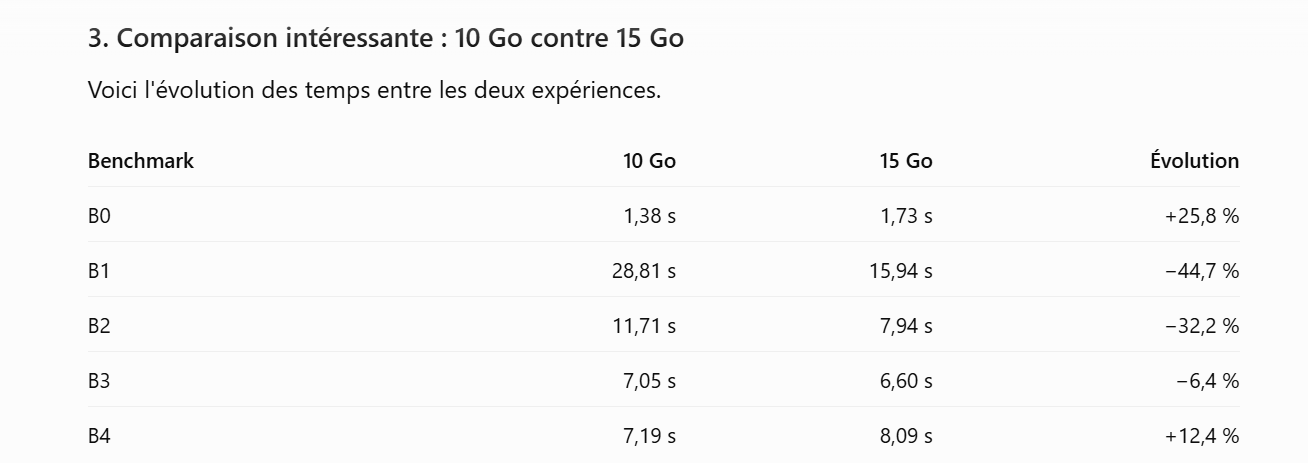

l'arbre a fait le choix le plus économique en nœuds parmi des options déjà hors délai (> 180 s), mais il n'a pas trouvé une configuration « optimale » qui résolve le problème sur 15 Go — parce que la limite de 180 s sur ce volume complet exige surtout de réduire le temps de décodage/E/S plutôt que d'ajuster uniquement (p, P) dans cette grille.